<a href="https://www.kaggle.com/code/yonasyifter/quantum-dynamics-1?scriptVersionId=367025312" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

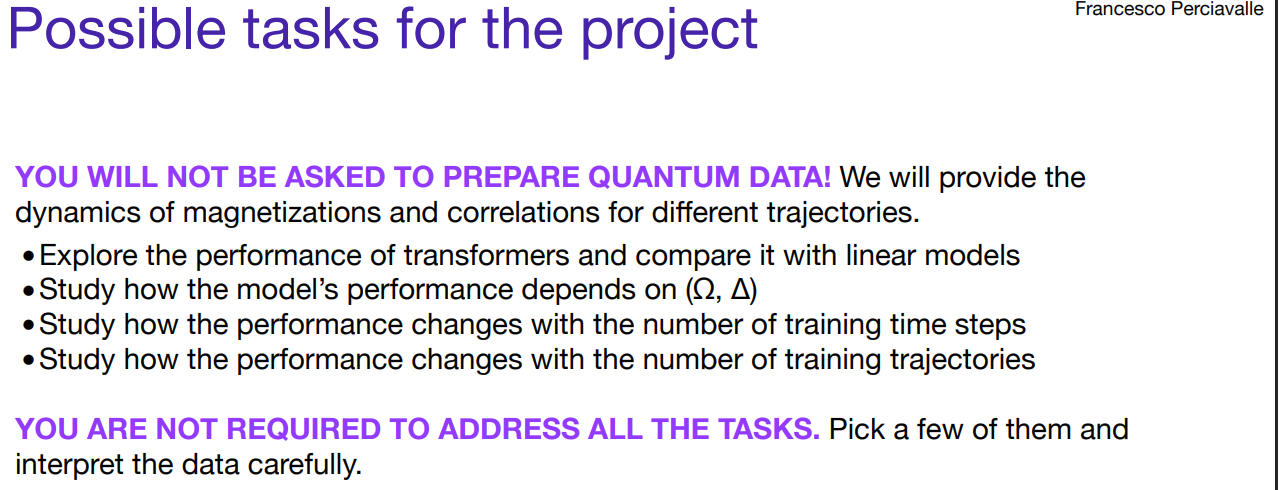

# Forecasting quantum chaotic many-body dynamics 


| # | Topic | Paper | Original notebook | This version |
|---|---|---|---|---|
| 2 | Physical system / data | PXP chain, $L=10$, initial states $\lvert\psi_{\lambda,\theta}\rangle$ (Eq. 2), $N=500$ trajectories | Kaggle CSVs with laser parameters $(\Omega,\Delta)$, a different dataset | exact-diagonalisation generator of the paper's dataset (`DATA_SOURCE="pxp"`); the Kaggle loader is kept as `DATA_SOURCE="kaggle"` |
| 3 | Time grid / windows | $T=800$, $\Delta t=0.02$, $\rho=500$ ($t\in[0,10)$), $\tau=300$ ($t\in[10,16)$) | 501 points, $\rho=250$, $\tau=251$ | paper values |
| 4 | Train/test split | first 100 trajectories = test, 400 = train+val, 30 % validation | first 400 = train, last 100 = test, 80 val (20 %) | paper split, seeded random 30 % validation split |
| 5 | Scaling | feature-wise Min–Max fitted on training trajectories only, inverted before metrics | **none** (heading says "Feature-Wise Scaling", code does nothing) | implemented; all reported metrics are in physical units |
| 6 | DLinear | moving-average $w=7$, L2 $=10^{-5}$, AdamW lr $10^{-3}$, wd $10^{-3}$, batch 64, ≤250 epochs, ReduceLROnPlateau, patience 10 | kernel 15/25, no L2, Adam, batch 32, 60 epochs, no scheduler; `AveragePooling1D(padding="same")` pads differently from DLinear's replicate padding | paper hyper-parameters, replicate-padded moving average, default (Glorot) initialisation; `init="inv_rho"` selects the reference-code initialisation (see Sec. 10 for why this matters) |
| 7 | **Transformer** | encoder–decoder, 7 layers, $d_{model}=256$, 2 heads, $d_{ff}=256$, **teacher forcing + recursive autoregressive inference**, causal mask, AdamW $3\cdot10^{-4}$, clip 1.0, batch 4, ≤100 epochs, patience 8 | one encoder block (4 heads, $d=64$), **direct multi-step** (dense over time axis), Adam | autoregressive encoder–decoder exactly as in Sec. 3.3.1 (direct-vs-autoregressive is the point of the comparison) |
| 8 | Positional encoding | not specified | `Embedding` on a raw `tf.range` tensor mixed with Keras tensors (fragile in Keras 3) | sinusoidal `Layer` (Vaswani et al.) |
| 9 | Loss | Eqs. 11–15, α=0.5, β=2 | correct | unchanged (already correct); now applied to scaled data as in the paper |
| 10 | Metrics | MAE, DA (Eqs. 17, 19, 20, 21) | correct formulas | unchanged; per-trajectory versions added |
| 11 | **Fig. 2** (DA/MAE over parameter space, raw + Savitzky–Golay) | present | **missing** (only MAE map) | added |
| 12 | Figs. 3, 4, 5 | present | present | kept; `boxplot(labels=)` made Matplotlib-version-safe |
| 13 | Hyper-parameter search | Hyperband / Bayesian | 3-fold CV on a 2-point grid; CI uses `np.std` (ddof=0) and a normal quantile with n=3 (too narrow) | CV kept (optional), CI uses ddof=1 and Student-t |
| 14 | Ablations use the same loss as the main models | same loss for both | ablations trained with plain MSE, evaluated with `model.evaluate` (which cannot run an autoregressive model) | same informed loss, unified `Forecaster.predict` |
| 15 | Shared `EarlyStopping` object across two `fit` calls | – | one callback instance reused | fresh callbacks per fit |
| 16 | Baselines | none in the paper | none | **added**: persistence and window-mean baselines, so the MAE of the models can be read against a trivial reference |
| 17 | Extras not in the paper | – | GRU baseline, $(\Omega,\Delta)$-conditioned Transformer, sample-complexity and input-horizon ablations | kept in Section 9 as *extensions* (conditioning is on $(\lambda,\theta)$ for PXP data) |

**Ambiguity in the paper.** Sec. 3.2.2 says the Transformer is trained to predict *only the next step* from a sliding window, while Sec. 3.3.1 says it uses an encoder–decoder with a teacher-forced shifted target of length $\tau$ (Eq. 16). This notebook follows Sec. 3.3.1, which is the more detailed description.

**Runtime.** The `paper` preset uses the full Transformer (7+7 layers, $d_{model}=256$), (7.4 M parameters). Measured on one CPU core: about 3 min per training epoch and about 12 s per test trajectory for the recursive decoding, so a GPU is strongly recommended (DLinear alone trains in about 2.5 min on CPU). Presets: `QD_PRESET=paper | quick | smoke` (environment variable, read in the next cell). `quick` keeps the data and DLinear identical and uses a small Transformer; `smoke` is a tiny end-to-end test.

# 1 Imports, Config & Reproducibility

In [2]:
import os, random, time, math
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")      # must be set before TF is imported to take effect
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from scipy.signal import savgol_filter
from scipy import stats
from sklearn.model_selection import KFold

SEED = 42

def set_reproducibility(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

set_reproducibility(SEED)


PRESET      = os.environ.get("QD_PRESET", "paper")      # "paper" | "quick" | "smoke"
DATA_SOURCE = os.environ.get("QD_DATA", "pxp")           # "pxp" (paper) | "kaggle" (original CSVs)

_dl_paper  = dict(w=7, l2=1e-5, lr=1e-3, wd=1e-3, bs=64, epochs=250, patience=10, lr_patience=4)
PRESETS = {
    "paper": dict(
        L=10, n_traj=500, T=800, dt=0.02, rho=500, n_test=100, val_frac=0.3,
        dl=_dl_paper,
        tf=dict(d_model=256, n_layers=7, n_heads=2, d_ff=256, dropout=0.1, lr=3e-4, wd=1e-3,
                clip=1.0, bs=4, epochs=100, patience=8, lr_patience=3),
        gru=dict(units=64, lr=1e-3, wd=1e-3, bs=64, epochs=100, patience=10, lr_patience=4),
        cv_epochs=25, cv_splits=3, cv_transformer=False,
        train_sizes=[25, 50, 100, 200, 400], rho_list=[100, 200, 300, 400, 500], abl_epochs=40,
        abl_tf=dict(d_model=64, n_layers=2, n_heads=2, d_ff=128, bs=16, lr=5e-4),   # lighter Transformer for ablations only
    ),
    "quick": dict(
        L=10, n_traj=500, T=800, dt=0.02, rho=500, n_test=100, val_frac=0.3,
        dl=dict(_dl_paper, epochs=100),
        tf=dict(d_model=64, n_layers=2, n_heads=2, d_ff=128, dropout=0.1, lr=5e-4, wd=1e-3,
                clip=1.0, bs=16, epochs=30, patience=6, lr_patience=3),
        gru=dict(units=64, lr=1e-3, wd=1e-3, bs=32, epochs=40, patience=8, lr_patience=3),
        cv_epochs=15, cv_splits=3, cv_transformer=True,
        train_sizes=[25, 50, 100, 200, 400], rho_list=[100, 200, 300, 400, 500], abl_epochs=20,
        abl_tf=dict(),
    ),
    "smoke": dict(
        L=6, n_traj=40, T=120, dt=0.1, rho=80, n_test=10, val_frac=0.3,
        dl=dict(_dl_paper, epochs=3, bs=8),
        tf=dict(d_model=16, n_layers=1, n_heads=2, d_ff=32, dropout=0.0, lr=1e-3, wd=1e-3,
                clip=1.0, bs=8, epochs=2, patience=3, lr_patience=2),
        gru=dict(units=8, lr=1e-3, wd=1e-3, bs=8, epochs=2, patience=3, lr_patience=2),
        cv_epochs=1, cv_splits=2, cv_transformer=True,
        train_sizes=[8, 16], rho_list=[20, 40, 80], abl_epochs=1,
        abl_tf=dict(),
    ),
}
CFG = PRESETS[PRESET]
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

print(f"TensorFlow {tf.__version__} | Keras {tf.keras.__version__} | seed {SEED} | preset = {PRESET} | data = {DATA_SOURCE}")
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.13.2 | seed 42 | preset = paper | data = pxp
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# 2 Data: PXP exact diagonalisation
**PXP model** (Eq. 1, open chain, $\Omega=1$): $\hat H=\Omega\big(X_1P_2+\sum_{j=2}^{L-1}P_{j-1}X_jP_{j+1}+P_{L-1}X_L\big)$, with $P_j=\lvert0\rangle\langle0\rvert_j$. It conserves the Rydberg-blockade subspace (no two adjacent $\lvert1\rangle$), which has dimension 144 for $L=10$, so exact time evolution is cheap.

**Initial states** (Eq. 2): $\lvert\psi_{\lambda,\theta}\rangle=\mathcal N[\lambda\lvert\Theta\rangle+(1-\lambda)\lvert\Theta'\rangle]$ with $\lvert\Theta\rangle=\lvert\theta,0,\theta,0,\dots\rangle$, $\lvert\Theta'\rangle=\lvert0,\theta,0,\theta,\dots\rangle$, $\lvert\theta\rangle=\cos\theta\lvert0\rangle+\sin\theta\lvert1\rangle$. Both lie in the blockade subspace. $(\lambda,\theta)$ are sampled uniformly in $[0,1]\times[0,\pi/2]$.

**Features** (Eq. 3): $L$ magnetisations $m^z_j=\langle Z_j\rangle$ followed by $L(L-1)/2$ connected correlators $c^{zz}_{jl}=\langle Z_jZ_l\rangle-\langle Z_j\rangle\langle Z_l\rangle$ ($j<l$, row-major), with $Z=\lvert1\rangle\langle1\rvert-\lvert0\rangle\langle0\rvert$ as in the paper, so $F=L(L+1)/2=55$ for $L=10$.

In [3]:
# ------------------------------ PXP generator ------------------------------
def pxp_basis(L):
    """Bitstrings with no two adjacent 1s (Rydberg blockade). Bit j <-> site j+1."""
    states = np.array([s for s in range(2 ** L) if (s & (s >> 1)) == 0], dtype=np.int64)
    bits = ((states[:, None] >> np.arange(L)[None, :]) & 1).astype(np.float64)
    return states, bits

def pxp_hamiltonian(L, omega=1.0):
    states, _ = pxp_basis(L)
    index = {int(s): i for i, s in enumerate(states)}
    H = np.zeros((len(states), len(states)))
    for s, i in index.items():
        for j in range(L):
            s2 = s ^ (1 << j)                      # flip site j; allowed iff the result is still blockade-consistent,
            if s2 in index:                        # i.e. both neighbours are |0> (P_{j-1} X_j P_{j+1}, open boundaries)
                H[index[s2], i] += omega
    return H

def staggered_amplitudes(bits, theta, sublattice):
    """Amplitudes of |theta,0,theta,0,...> (sublattice=0) or |0,theta,0,theta,...> (sublattice=1) in the blockade basis."""
    L = bits.shape[1]
    amp = np.ones(len(bits))
    for j in range(L):
        if j % 2 == sublattice:
            amp *= np.where(bits[:, j] == 1, np.sin(theta), np.cos(theta))
        else:
            amp *= (bits[:, j] == 0)
    return amp

def initial_state(lam, theta, bits):
    psi = lam * staggered_amplitudes(bits, theta, 0) + (1 - lam) * staggered_amplitudes(bits, theta, 1)
    return psi / np.linalg.norm(psi)               # N(lambda, theta)

def generate_pxp_dataset(L, n_traj, T, dt, seed=SEED, omega=1.0):
    rng = np.random.default_rng(seed)
    _, bits = pxp_basis(L)
    H = pxp_hamiltonian(L, omega)
    E, V = np.linalg.eigh(H)
    t = np.arange(T) * dt                          # t_i = (i-1) dt
    phases = np.exp(-1j * np.outer(t, E))          # (T, dim)
    z = 2.0 * bits - 1.0                           # Z=+1 for |1>, -1 for |0>
    pairs = [(j, l) for j in range(L) for l in range(j + 1, L)]
    js, ls = np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs])
    zz = z[:, js] * z[:, ls]
    lam = rng.uniform(0.0, 1.0, n_traj)
    theta = rng.uniform(0.0, np.pi / 2, n_traj)
    obs = np.empty((n_traj, T, L + len(pairs)), dtype=np.float32)
    for k in range(n_traj):
        c = V.T @ initial_state(lam[k], theta[k], bits)
        probs = np.abs((phases * c) @ V.T) ** 2    # |<s|psi(t)>|^2, (T, dim)
        assert np.allclose(probs.sum(1), 1.0, atol=1e-8), "norm not conserved"
        m = probs @ z
        obs[k, :, :L] = m
        obs[k, :, L:] = probs @ zz - m[:, js] * m[:, ls]
    return obs, np.stack([lam, theta], 1).astype(np.float32), t.astype(np.float32)

# ------------------------------ original Kaggle loader (kept) ------------------------------
KAGGLE_PARAM_PATH = "/kaggle/input/datasets/yonasyifter/quantum-dynamics/dataN10/dataN10/parameters_ed.csv"
KAGGLE_TRAJ_PATH  = "/kaggle/input/datasets/yonasyifter/quantum-dynamics/dataN10/dataN10/trajectories_ed.csv"

def load_kaggle_dataset(param_path=KAGGLE_PARAM_PATH, traj_path=KAGGLE_TRAJ_PATH):
    df_params = pd.read_csv(param_path)
    params = df_params[["Omega", "Delta"]].values.astype(np.float32)
    assert not np.isnan(params).any(), "NaN values found in parameters!"
    df_traj = pd.read_csv(traj_path, header=None, low_memory=False)
    if not pd.to_numeric(df_traj.iloc[0], errors="coerce").notna().all():     # header row present
        df_traj = df_traj.iloc[1:].reset_index(drop=True)
    raw = df_traj.apply(pd.to_numeric).values.astype(np.float32)
    assert np.isfinite(raw).all(), "NaN/Inf values found in trajectories!"
    n_rows, n_cols = raw.shape
    t = raw[:, 0]
    starts = np.concatenate([[0], np.where(np.diff(t) < 0)[0] + 1])
    if len(starts) > 1:
        n_traj = len(starts)
        lens = np.diff(np.concatenate([starts, [n_rows]]))
        assert np.all(lens == lens[0]), f"Uneven trajectory lengths: {np.unique(lens)}"
        n_points = int(lens[0])
    else:
        n_traj = len(df_params)
        assert n_rows % n_traj == 0
        n_points = n_rows // n_traj
    assert n_traj == len(df_params), f"{n_traj} trajectories vs {len(df_params)} parameter rows"
    traj = raw.reshape(n_traj, n_points, n_cols)
    assert np.allclose(traj[:, :, 0], traj[0, :, 0], atol=1e-3), "time grids differ between trajectories"
    return traj[:, :, 1:], params, traj[0, :, 0]

# ------------------------------ choose the data source ------------------------------
if DATA_SOURCE == "pxp":
    L = CFG["L"]
    t0 = time.time()
    observables, params, time_grid = generate_pxp_dataset(L, CFG["n_traj"], CFG["T"], CFG["dt"])
    print(f"Generated PXP dataset in {time.time()-t0:.1f}s")
    PARAM_LABELS = ("λ", "θ/(π/2)")
    params_plot = np.stack([params[:, 0], params[:, 1] / (np.pi / 2)], 1)   # coordinates used in all parameter-plane plots
    RHO = CFG["rho"]
else:
    observables, params, time_grid = load_kaggle_dataset()
    L = 10
    PARAM_LABELS = ("Ω", "Δ")
    params_plot = params
    RHO = 250                                       # original notebook's input window

N_TRAJ, T, F = observables.shape
N_MAG, N_CORR = L, F - L
TAU = T - RHO
DT = float(time_grid[1] - time_grid[0])
assert F == L * (L + 1) // 2, f"expected F = L(L+1)/2 = {L*(L+1)//2}, got {F}"
assert np.isfinite(observables).all()

print(f"observables: {observables.shape}  (N_TRAJ={N_TRAJ}, T={T}, F={F}; {N_MAG} magnetisations + {N_CORR} connected correlators)")
print(f"dt = {DT:.4f}; input window rho = {RHO} (t in [{time_grid[0]:.2f}, {time_grid[RHO-1]:.2f}]), horizon tau = {TAU} (t in [{time_grid[RHO]:.2f}, {time_grid[-1]:.2f}])")
print(f"magnetisation range [{observables[:, :, :N_MAG].min():.3f}, {observables[:, :, :N_MAG].max():.3f}]  | correlator range [{observables[:, :, N_MAG:].min():.3f}, {observables[:, :, N_MAG:].max():.3f}]")

Generated PXP dataset in 1.7s
observables: (500, 800, 55)  (N_TRAJ=500, T=800, F=55; 10 magnetisations + 45 connected correlators)
dt = 0.0200; input window rho = 500 (t in [0.00, 9.98]), horizon tau = 300 (t in [10.00, 15.98])
magnetisation range [-1.000, 0.997]  | correlator range [-0.974, 0.974]


Neel |1010..>      <Z_j>(0) = [ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.]
polarised |000..>  <Z_j>(0) = [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


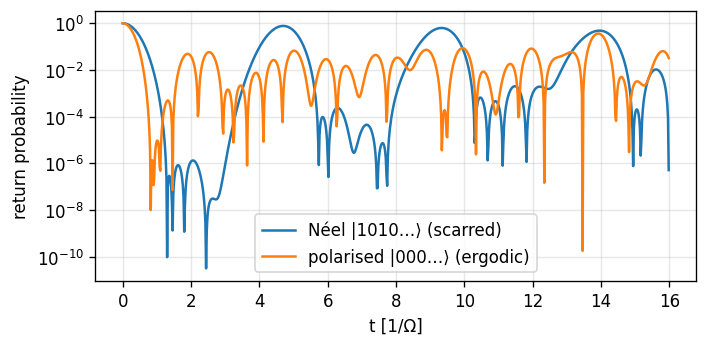

In [4]:
# ---- physical sanity checks on the generated data (PXP only) ----
if DATA_SOURCE == "pxp":
    assert observables[:, :, :N_MAG].min() >= -1 - 1e-5 and observables[:, :, :N_MAG].max() <= 1 + 1e-5
    # Neel state |1010...> (lambda=1, theta=pi/2): m_j(0) = +1, -1, +1, ... ; fully polarised |000...> (theta=0): m_j(0) = -1
    _, bits_ = pxp_basis(L)
    for lam_, th_, name in [(1.0, np.pi / 2, "Neel |1010..>"), (0.5, 0.0, "polarised |000..>")]:
        psi_ = initial_state(lam_, th_, bits_)
        print(f"{name:18s} <Z_j>(0) =", np.round((psi_**2) @ (2 * bits_ - 1), 3))
    # Scar revivals: the Neel state should revive with period ~ 4.7 / Omega, the polarised state should not.
    E_, V_ = np.linalg.eigh(pxp_hamiltonian(L))
    tt = np.arange(0, 16, 0.02)
    def fidelity(psi0):
        c = V_.T @ psi0
        return np.abs((np.exp(-1j * np.outer(tt, E_)) * c) @ (V_.T @ psi0)) ** 2
    f_neel, f_pol = fidelity(initial_state(1.0, np.pi / 2, bits_)), fidelity(initial_state(0.5, 0.0, bits_))
    fig, ax = plt.subplots(figsize=(6, 3), dpi=120)
    ax.plot(tt, f_neel, label="Néel |1010…⟩ (scarred)"); ax.plot(tt, f_pol, label="polarised |000…⟩ (ergodic)")
    ax.set_xlabel("t [1/Ω]"); ax.set_ylabel("return probability"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

# 3 Trajectory split, temporal split & feature-wise Min–Max scaling (paper Sec. 3.3)

* The **first $N_{test}=100$ trajectories are held out for testing**, the remaining 400 form the training+validation pool (the split is at trajectory level, before any preprocessing).
* A feature-wise Min–Max map to $[0,1]$ is **fitted on the training pool only** and applied to the test set unchanged. Predictions are mapped back to physical units before any metric is computed.
* Input $X^{in}$ = first $\rho$ steps, target $X^{out}$ = following $\tau$ steps. The 30 % validation split is taken inside `Forecaster.fit` from the training pool.

In [5]:
N_TEST = CFG["n_test"] if DATA_SOURCE == "pxp" else 100
obs_test_raw, obs_dev_raw = observables[:N_TEST], observables[N_TEST:]
P_test, P_dev = params[:N_TEST], params[N_TEST:]
P_test_plot = params_plot[:N_TEST]

# --- feature-wise Min-Max, fitted on the training pool only (over trajectories and all time steps)
f_min = obs_dev_raw.min(axis=(0, 1))
f_rng = obs_dev_raw.max(axis=(0, 1)) - f_min
f_rng = np.where(f_rng > 1e-12, f_rng, 1.0).astype(np.float32)
to_scaled = lambda a: ((a - f_min) / f_rng).astype(np.float32)
to_phys   = lambda a: (a * f_rng + f_min).astype(np.float32)

# parameters (only used by the conditioned-Transformer extension)
p_min, p_rng = P_dev.min(0), np.maximum(P_dev.max(0) - P_dev.min(0), 1e-12)
P_dev_s, P_test_s = ((P_dev - p_min) / p_rng).astype(np.float32), ((P_test - p_min) / p_rng).astype(np.float32)

obs_dev_s, obs_test_s = to_scaled(obs_dev_raw), to_scaled(obs_test_raw)
X_dev,  Y_dev  = obs_dev_s[:, :RHO],  obs_dev_s[:, RHO:]
X_test, Y_test = obs_test_s[:, :RHO], obs_test_s[:, RHO:]          # scaled space (model space)
X_test_phys, Y_test_phys = obs_test_raw[:, :RHO], obs_test_raw[:, RHO:]   # physical space (evaluation space)

assert X_dev.shape == (N_TRAJ - N_TEST, RHO, F) and Y_dev.shape[1] == TAU
assert X_dev.min() >= -1e-6 and X_dev.max() <= 1 + 1e-6, "training data not in [0,1]"
print(f"train+val pool: X {X_dev.shape} -> Y {Y_dev.shape} | test: X {X_test.shape} -> Y {Y_test.shape}")
print(f"test data in scaled space: min {obs_test_s.min():.3f}, max {obs_test_s.max():.3f} (may slightly exceed [0,1]; the map is not refitted)")

train+val pool: X (400, 500, 55) -> Y (400, 300, 55) | test: X (100, 500, 55) -> Y (100, 300, 55)
test data in scaled space: min -0.056, max 1.050 (may slightly exceed [0,1]; the map is not refitted)


# 4 Informed composite loss, metrics, models and a unified `Forecaster`

**Loss** (Eqs. 11–15, identical for every model): $\mathcal L=\mathcal L_{pos}+\alpha\mathcal L_{dir}+\beta\mathcal L_{sign}$, $\alpha=0.5,\ \beta=2$.
**Metrics** (Eqs. 17, 19–21): MAE and directional accuracy (DA), per trajectory and globally, always on physical-unit predictions.

**Models**
* **DLinear** — direct multi-step; moving-average trend/seasonal split (replicate padding, $w=7$) + two *shared-across-features* linear layers $\rho\to\tau$ (default random initialisation; `init="inv_rho"` gives the reference-code initialisation).
* **Transformer** — encoder–decoder, teacher forcing with shifted target $D_k=(0,x_{\rho+1},\dots,x_{\rho+\tau-1})$ (Eq. 16) and a causal mask; at inference the decoder starts from zeros and is filled recursively with its own predictions.
* *(extension)* GRU baseline and a parameter-conditioned Transformer.

In [6]:
# ------------------------- loss (paper Eqs. 11-15) -------------------------
def informed_composite_loss(alpha=0.5, beta=2.0):
    def loss_fn(y_true, y_pred):
        l_pos  = tf.reduce_mean(tf.square(y_true - y_pred))                          # Eq. 11
        dy_t   = y_true[:, 1:, :] - y_true[:, :-1, :]                                # Eq. 12
        dy_p   = y_pred[:, 1:, :] - y_pred[:, :-1, :]
        l_dir  = tf.reduce_mean(tf.square(dy_t - dy_p))                              # Eq. 13
        l_sign = tf.reduce_mean(tf.nn.relu(-dy_t * dy_p))                            # Eq. 14
        return l_pos + alpha * l_dir + beta * l_sign                                 # Eq. 15
    return loss_fn

# ------------------------- metrics (paper Eqs. 17, 19-21) -------------------------
def mae_per_traj(Y, P):                       # Eq. 20, shape (N,)
    return np.mean(np.abs(P - Y), axis=(1, 2))

def da_per_traj(Y, P, x_last):                # Eq. 21 (+ Eq. 19 reference: x~_rho = x_rho), shape (N,)
    ref = x_last[:, -1:, :]
    d_true = np.diff(np.concatenate([ref, Y], axis=1), axis=1)
    d_pred = np.diff(np.concatenate([ref, P], axis=1), axis=1)
    return 100.0 * np.mean(np.sign(d_true) == np.sign(d_pred), axis=(1, 2))

def compute_directional_accuracy(Y, P, x_last):          # global DA, Eq. 19
    return float(da_per_traj(Y, P, x_last).mean())

# ------------------------- custom layers -------------------------
class MovingAvgReplicate(layers.Layer):
    """DLinear moving average: replicate-pad both ends by (k-1)/2, then average with stride 1."""
    def __init__(self, kernel_size, **kw):
        super().__init__(**kw)
        assert kernel_size % 2 == 1, "moving-average window must be odd"
        self.k = kernel_size
    def call(self, x):
        pad = (self.k - 1) // 2
        xp = tf.concat([tf.repeat(x[:, :1], pad, axis=1), x, tf.repeat(x[:, -1:], pad, axis=1)], axis=1)
        return tf.nn.avg_pool1d(xp, ksize=self.k, strides=1, padding="VALID")
    def compute_output_shape(self, input_shape):
        return input_shape
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.k}

class SinusoidalPE(layers.Layer):
    """Fixed sinusoidal positional encoding (Vaswani et al.); works for any sequence length."""
    def call(self, x):
        d = x.shape[-1]
        pos = tf.cast(tf.range(tf.shape(x)[1])[:, None], tf.float32)
        i = tf.cast(tf.range(0, d, 2)[None, :], tf.float32)
        ang = pos / tf.pow(10000.0, i / d)
        pe = tf.concat([tf.sin(ang), tf.cos(ang)], axis=-1)
        return x + pe[None]
    def compute_output_shape(self, input_shape):
        return input_shape

# ------------------------- architectures -------------------------
def build_dlinear(rho, tau, F, w=7, l2=1e-5, init="glorot", **_):
    inp = layers.Input(shape=(rho, F), name="past")
    trend = MovingAvgReplicate(w)(inp)
    seasonal = layers.Subtract()([inp, trend])
    reg = tf.keras.regularizers.l2(l2)
    init = tf.keras.initializers.Constant(1.0 / rho) if init == "inv_rho" else "glorot_uniform"   # "inv_rho" = constant 1/rho init of the reference DLinear code; default Keras Glorot init is what reproduces the paper (see Sec. 10)
    def proj(x):    # Dense acts on the time axis, weights shared across the F features
        x = layers.Permute((2, 1))(x)
        return layers.Dense(tau, kernel_initializer=init, kernel_regularizer=reg)(x)
    out = layers.Permute((2, 1))(layers.Add()([proj(trend), proj(seasonal)]))
    return models.Model(inp, out, name="DLinear")

def build_gru(rho, tau, F, units=64, **_):
    inp = layers.Input(shape=(rho, F), name="past")
    x = layers.GRU(units)(inp)
    x = layers.Dense(tau * F)(x)
    return models.Model(inp, layers.Reshape((tau, F))(x), name="GRU")

def build_transformer_ar(rho, tau, F, d_model=256, n_layers=7, n_heads=2, d_ff=256, dropout=0.1, cond_dim=0, **_):
    """Encoder-decoder Transformer. Returns (train_model, encoder, decoder).
    train_model inputs: [past (rho,F), shifted_target (tau,F), (params)] -> (tau,F)
    decoder accepts any target length, which is what the recursive inference loop relies on."""
    assert d_model % 2 == 0 and d_model % n_heads == 0
    key_dim = d_model // n_heads
    mha = lambda: layers.MultiHeadAttention(num_heads=n_heads, key_dim=key_dim, dropout=dropout)
    ln  = lambda: layers.LayerNormalization(epsilon=1e-5)

    def embed(x, p):
        x = SinusoidalPE()(layers.Dense(d_model)(x))
        if p is not None:
            pe = layers.Dense(d_model)(layers.Dense(d_model, activation="gelu")(p))
            x = x + layers.Reshape((1, d_model))(pe)                         # broadcast over time
        return layers.Dropout(dropout)(x)

    def ffn(x):
        return layers.Dense(d_model)(layers.Dense(d_ff, activation="relu")(x))

    # ---- encoder
    e_in = layers.Input((rho, F)); e_p = layers.Input((cond_dim,)) if cond_dim else None
    x = embed(e_in, e_p)
    for _ in range(n_layers):
        x = ln()(x + layers.Dropout(dropout)(mha()(x, x)))
        x = ln()(x + layers.Dropout(dropout)(ffn(x)))
    encoder = models.Model([e_in] + ([e_p] if cond_dim else []), x, name="encoder")

    # ---- decoder (causal self-attention + cross-attention)
    d_in = layers.Input((None, F)); mem = layers.Input((rho, d_model)); d_p = layers.Input((cond_dim,)) if cond_dim else None
    y = embed(d_in, d_p)
    for _ in range(n_layers):
        y = ln()(y + layers.Dropout(dropout)(mha()(y, y, use_causal_mask=True)))
        y = ln()(y + layers.Dropout(dropout)(mha()(y, mem)))
        y = ln()(y + layers.Dropout(dropout)(ffn(y)))
    decoder = models.Model([d_in, mem] + ([d_p] if cond_dim else []), layers.Dense(F)(y), name="decoder")

    # ---- joint training model
    j_e = layers.Input((rho, F)); j_d = layers.Input((tau, F)); j_p = layers.Input((cond_dim,)) if cond_dim else None
    pj = [j_p] if cond_dim else []
    out = decoder([j_d, encoder([j_e] + pj)] + pj)
    return models.Model([j_e, j_d] + pj, out, name="Transformer"), encoder, decoder

def shift_target(Y):                 # Eq. 16: D = (0, x_{rho+1}, ..., x_{rho+tau-1})
    return np.concatenate([np.zeros_like(Y[:, :1]), Y[:, :-1]], axis=1)

In [7]:
class Forecaster:
    """Uniform fit/predict interface for 'dlinear', 'gru' and 'transformer' (optionally parameter-conditioned).
    Works in scaled space. predict() runs the recursive decoding loop for the Transformer."""
    CFG_KEY = {"dlinear": "dl", "gru": "gru", "transformer": "tf"}

    def __init__(self, kind, rho, tau, F, hp=None, cond_dim=0, seed=SEED, informed=True):
        self.kind, self.rho, self.tau, self.F, self.cond_dim, self.seed, self.informed = kind, rho, tau, F, cond_dim, seed, informed
        self.hp = dict(CFG[self.CFG_KEY[kind]]); self.hp.update(hp or {})
        set_reproducibility(seed)
        if kind == "dlinear":
            self.model = build_dlinear(rho, tau, F, **self.hp)
        elif kind == "gru":
            self.model = build_gru(rho, tau, F, **self.hp)
        elif kind == "transformer":
            self.model, self.encoder, self.decoder = build_transformer_ar(rho, tau, F, cond_dim=cond_dim, **self.hp)
            self._dec_step = tf.function(lambda inputs: self.decoder(inputs, training=False), reduce_retracing=True)
        else:
            raise ValueError(kind)

    # --- helpers
    def _inputs(self, X, Y=None, P=None):
        xs = [X]
        if self.kind == "transformer":
            xs.append(shift_target(Y))                     # teacher forcing
        if self.cond_dim:
            xs.append(P)
        return xs if len(xs) > 1 else X

    def fit(self, X, Y, P=None, val_frac=None, epochs=None, verbose=0):
        hp = self.hp
        val_frac = CFG["val_frac"] if val_frac is None else val_frac
        idx = np.random.default_rng(self.seed).permutation(len(X))
        n_val = max(1, int(round(val_frac * len(X))))
        va, tr = idx[:n_val], idx[n_val:]
        take = lambda a, i: None if a is None else a[i]
        opt = tf.keras.optimizers.AdamW(learning_rate=hp["lr"], weight_decay=hp["wd"],
                                        **({"clipnorm": hp["clip"]} if "clip" in hp else {}))
        self.model.compile(optimizer=opt, loss=informed_composite_loss() if self.informed else "mse", metrics=["mae"])
        cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=hp["patience"], restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=hp["lr_patience"], min_lr=1e-6)]
        h = self.model.fit(self._inputs(X[tr], Y[tr], take(P, tr)), Y[tr],
                           validation_data=(self._inputs(X[va], Y[va], take(P, va)), Y[va]),
                           epochs=epochs or hp["epochs"], batch_size=min(hp["bs"], len(tr)), callbacks=cbs, verbose=verbose)
        self.history, self.n_epochs = h.history, len(h.epoch)
        return self

    def predict(self, X, P=None, batch_size=32):
        if self.kind != "transformer":
            return self.model.predict(X, batch_size=64, verbose=0)
        outs = []
        for s in range(0, len(X), batch_size):
            xb = tf.constant(X[s:s + batch_size]); pb = [tf.constant(P[s:s + batch_size])] if self.cond_dim else []
            mem = self.encoder([xb] + pb, training=False)
            buf = tf.zeros((xb.shape[0], 1, self.F))               # decoder input starts from the zero vector
            for _ in range(self.tau):                              # recursive filling with own predictions
                nxt = self._dec_step([buf, mem] + pb)[:, -1:, :]
                buf = tf.concat([buf, nxt], axis=1)
            outs.append(buf[:, 1:, :].numpy())
        return np.concatenate(outs, 0)

# --- quick shape/consistency test of the autoregressive decoding (tiny model, runs in seconds) ---
_chk = Forecaster("transformer", 12, 5, 4, hp=dict(d_model=8, n_layers=1, n_heads=2, d_ff=16, dropout=0.0))
_x = np.random.rand(3, 12, 4).astype("float32"); _y = np.random.rand(3, 5, 4).astype("float32")
_tf_out = _chk.model.predict([_x, shift_target(_y)], verbose=0)
# causality check: output at step i must not depend on decoder inputs at positions > i
_d2 = shift_target(_y).copy(); _d2[:, 3:] += 1.0
assert np.allclose(_tf_out[:, :3], _chk.model.predict([_x, _d2], verbose=0)[:, :3], atol=1e-5), "decoder mask is not causal"
assert _chk.predict(_x).shape == (3, 5, 4)
print("Forecaster self-test passed (causal mask + recursive decoding shapes).")

E0000 00:00:1793828973.870744      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Forecaster self-test passed (causal mask + recursive decoding shapes).


# 5 Hyper-parameter cross-validation (optional, replaces the paper's Hyperband / Bayesian search)

The paper's selected hyper-parameters are already the defaults in `CFG`. This section is kept from the original notebook as a sanity check on small grids. Fixes relative to the original: models use the informed loss, metrics are computed in physical units, and the 95 % interval uses Student-$t$ with `ddof=1` (the original used a normal quantile with the population std on 3 folds, which is too narrow). The full-size Transformer is skipped in the `paper` preset (set `CFG["cv_transformer"]=True` to force it).

In [8]:
def run_cv_benchmark(kind, hp_grid, X, Y, n_splits=None, epochs=None):
    n_splits = n_splits or CFG["cv_splits"]; epochs = epochs or CFG["cv_epochs"]
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    tcrit = stats.t.ppf(0.975, df=n_splits - 1)
    records = []
    for name, hp in hp_grid.items():
        mses, maes, das, secs = [], [], [], []
        for fold, (tr, va) in enumerate(kf.split(X)):
            fc = Forecaster(kind, RHO, TAU, F, hp=hp, seed=SEED + fold)
            t0 = time.time(); fc.fit(X[tr], Y[tr], epochs=epochs); secs.append((time.time() - t0) / fc.n_epochs)
            pred, true = to_phys(fc.predict(X[va])), to_phys(Y[va])          # physical units
            mses.append(np.mean((true - pred) ** 2)); maes.append(np.mean(np.abs(true - pred)))
            das.append(compute_directional_accuracy(true, pred, to_phys(X[va])))
        ci = lambda v: tcrit * np.std(v, ddof=1) / np.sqrt(n_splits)
        records.append({"Model & Hp Config": name,
                        "Val MSE (mean ± 95% CI)": f"{np.mean(mses):.6f} ± {ci(mses):.6f}",
                        "Val MAE (mean ± 95% CI)": f"{np.mean(maes):.6f} ± {ci(maes):.6f}",
                        "Val DA % (mean ± 95% CI)": f"{np.mean(das):.2f} ± {ci(das):.2f}",
                        "Time/epoch (s)": f"{np.mean(secs):.3f}"})
    return pd.DataFrame(records)

HP_GRIDS = {
    "dlinear": {"DLinear w=7  lr=1e-3 (paper)": dict(w=7, lr=1e-3),
                "DLinear w=7  lr=1e-2":         dict(w=7, lr=1e-2),
                "DLinear w=25 lr=1e-3":         dict(w=25, lr=1e-3)},
    "gru":     {"GRU n=32 lr=1e-2": dict(units=32, lr=1e-2),
                "GRU n=64 lr=1e-3": dict(units=64, lr=1e-3)},
    "transformer": {"Transformer d=32 h=2 L=1": dict(d_model=32, n_heads=2, n_layers=1, d_ff=64, bs=16, lr=5e-4),
                    "Transformer d=64 h=2 L=2": dict(d_model=64, n_heads=2, n_layers=2, d_ff=128, bs=16, lr=5e-4)},
}
RUN_CV = True
if RUN_CV:
    parts = [run_cv_benchmark("dlinear", HP_GRIDS["dlinear"], X_dev, Y_dev),
             run_cv_benchmark("gru", HP_GRIDS["gru"], X_dev, Y_dev)]
    if CFG["cv_transformer"]:
        parts.append(run_cv_benchmark("transformer", HP_GRIDS["transformer"], X_dev, Y_dev))
    df_res = pd.concat(parts, ignore_index=True)
    display(df_res)

E0000 00:00:1793828979.327919      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793828985.227853      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

E0000 00:00:1793828991.065234      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793828996.809840      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793829002.631102      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Model & Hp Config,Val MSE (mean ± 95% CI),Val MAE (mean ± 95% CI),Val DA % (mean ± 95% CI),Time/epoch (s)
0,DLinear w=7 lr=1e-3 (paper),0.019584 ± 0.002740,0.102246 ± 0.006302,50.80 ± 0.39,0.222
1,DLinear w=7 lr=1e-2,0.015523 ± 0.001783,0.094357 ± 0.005143,50.95 ± 0.34,0.217
2,DLinear w=25 lr=1e-3,0.016436 ± 0.002407,0.092488 ± 0.005834,51.30 ± 0.35,0.232
3,GRU n=32 lr=1e-2,0.005284 ± 0.001373,0.051842 ± 0.006624,68.54 ± 5.18,0.281
4,GRU n=64 lr=1e-3,0.018840 ± 0.000635,0.102087 ± 0.001200,57.45 ± 0.81,0.280


# 6 Final training, evaluation and Fig. 2 (performance over the parameter plane)

Both models are trained on the same 400-trajectory pool (30 % internal validation split) with the same informed loss. Everything below is evaluated on the 100 held-out test trajectories in **physical units**. Two trivial baselines are added for reference (not in the paper): *persistence* (repeat the last observed value) and *window mean*.

In [9]:
t0 = time.time()
fc_dl = Forecaster("dlinear", RHO, TAU, F).fit(X_dev, Y_dev, verbose=0)
print(f"DLinear     : {fc_dl.model.count_params():>9,} params | {fc_dl.n_epochs} epochs | {time.time()-t0:.0f}s")
t0 = time.time()
fc_tf = Forecaster("transformer", RHO, TAU, F).fit(X_dev, Y_dev, verbose=0)
print(f"Transformer : {fc_tf.model.count_params():>9,} params | {fc_tf.n_epochs} epochs | {time.time()-t0:.0f}s")

t0 = time.time()
pred_dl = to_phys(fc_dl.predict(X_test))                 # direct multi-step, physical units
pred_tf = to_phys(fc_tf.predict(X_test))                 # recursive decoding, physical units
print(f"inference done in {time.time()-t0:.0f}s")

pred_persist = np.repeat(X_test_phys[:, -1:, :], TAU, axis=1)
pred_wmean   = np.repeat(X_test_phys.mean(axis=1, keepdims=True), TAU, axis=1)

rows = []
for name, pr in [("DLinear", pred_dl), ("Transformer", pred_tf), ("Persistence (last value)", pred_persist), ("Window mean", pred_wmean)]:
    is_model = name in ("DLinear", "Transformer")
    rows.append({"Model": name,
                 "MAE total": np.mean(np.abs(Y_test_phys - pr)),
                 "MAE magnetisations": np.mean(np.abs(Y_test_phys[:, :, :N_MAG] - pr[:, :, :N_MAG])),
                 "MAE correlators":    np.mean(np.abs(Y_test_phys[:, :, N_MAG:] - pr[:, :, N_MAG:])),
                 "DA % (raw)": compute_directional_accuracy(Y_test_phys, pr, X_test_phys) if is_model else np.nan})
df_eval = pd.DataFrame(rows).set_index("Model")
display(df_eval.style.format("{:.5f}", subset=df_eval.columns[:3]).format("{:.2f}", subset=["DA % (raw)"], na_rep="n/a"))

DLinear     :   300,600 params | 250 epochs | 48s
Transformer : 7,429,431 params | 100 epochs | 978s


E0000 00:00:1793830102.987914      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (32, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnin

inference done in 59s


,MAE total,MAE magnetisations,MAE correlators,DA % (raw)
Model,,,,
DLinear,0.06378,0.08747,0.05852,56.14
Transformer,0.05444,0.12266,0.03928,79.34
Persistence (last value),0.12543,0.21936,0.10456,n/a
Window mean,0.10419,0.15797,0.09223,n/a


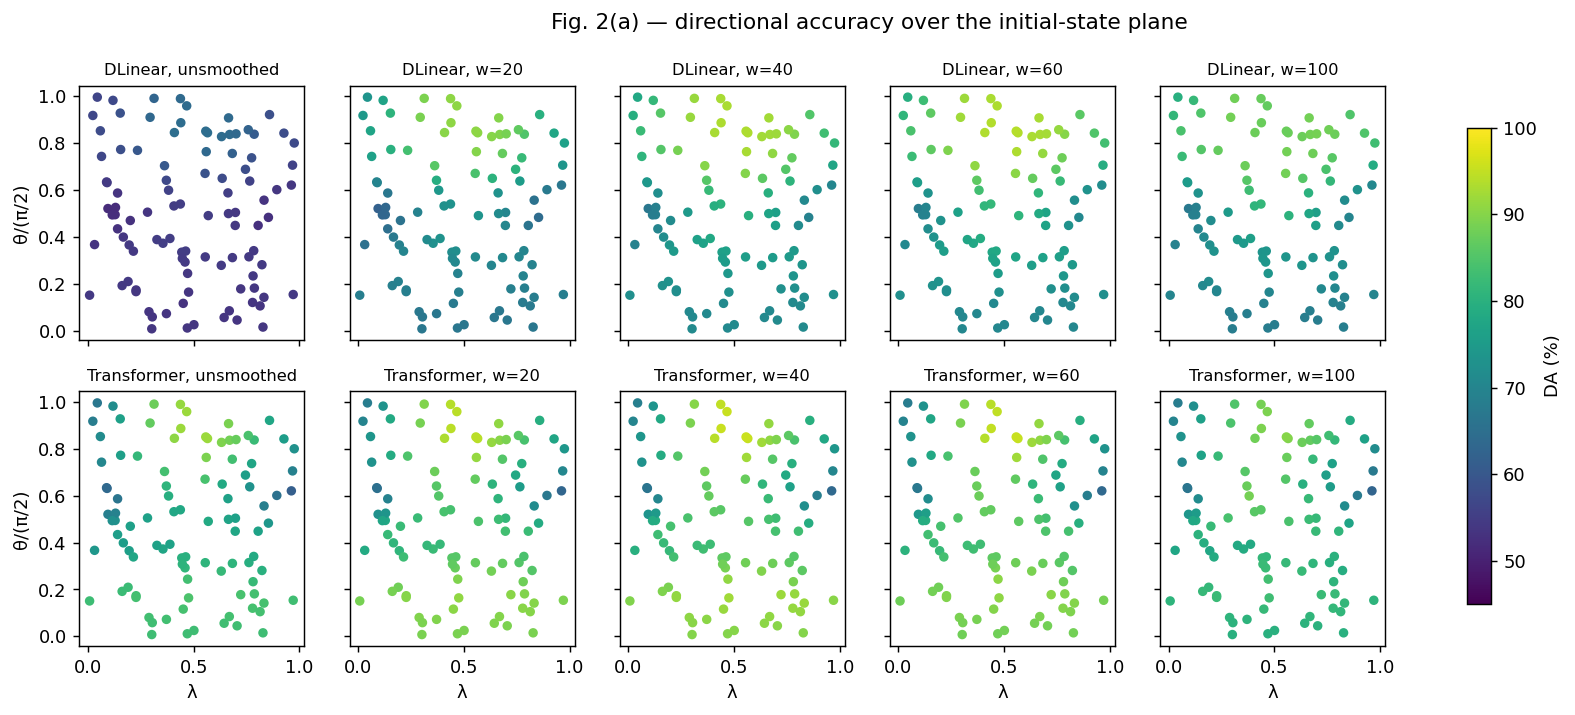

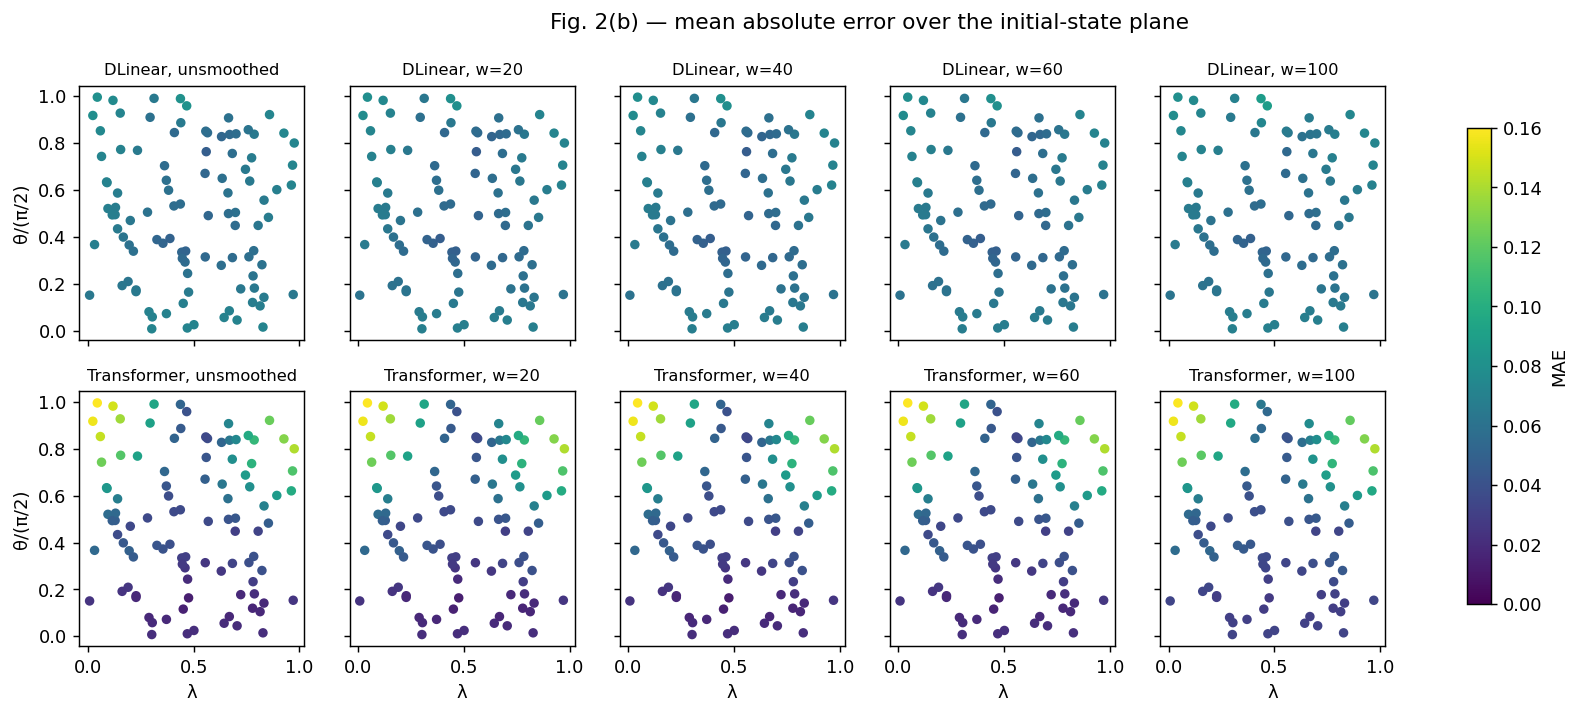

In [10]:
# ---------------- Fig. 2: DA_k and MAE_k over the parameter plane, raw and Savitzky-Golay smoothed ----------------
def smooth_pred(pred, w):
    if w is None:
        return pred
    w_eff = w if w % 2 == 1 else w + 1                      # savgol needs an odd window
    return savgol_filter(pred, w_eff, polyorder=2, axis=1)  # second-order polynomial, as in the paper

SG_WINDOWS = [w for w in (20, 40, 60, 100) if (w if w % 2 else w + 1) <= TAU]
VARIANTS   = [None] + SG_WINDOWS
maps = {}                                                    # (model, w) -> (MAE_k, DA_k)
for model_name, pr in [("DLinear", pred_dl), ("Transformer", pred_tf)]:
    for w in VARIANTS:
        ps = smooth_pred(pr, w)
        maps[(model_name, w)] = (mae_per_traj(Y_test_phys, ps), da_per_traj(Y_test_phys, ps, X_test_phys))

def plot_param_maps(idx, title, cbar_label, fname, vmin=None, vmax=None):
    ncol = len(VARIANTS)
    fig, axes = plt.subplots(2, ncol, figsize=(3.0 * ncol + 1.2, 5.6), dpi=130, sharex=True, sharey=True, squeeze=False)
    for r, model_name in enumerate(["DLinear", "Transformer"]):
        for c, w in enumerate(VARIANTS):
            ax = axes[r, c]
            sc = ax.scatter(P_test_plot[:, 0], P_test_plot[:, 1], c=maps[(model_name, w)][idx], s=18, cmap="viridis", vmin=vmin, vmax=vmax)
            ax.set_title(f"{model_name}, {'unsmoothed' if w is None else f'w={w}'}", fontsize=9)
            if c == 0: ax.set_ylabel(PARAM_LABELS[1])
            if r == 1: ax.set_xlabel(PARAM_LABELS[0])
    fig.suptitle(title); fig.colorbar(sc, ax=axes.ravel().tolist(), label=cbar_label, shrink=0.85)
    plt.savefig(f"{FIG_DIR}/{fname}", dpi=200, bbox_inches="tight"); plt.show()

plot_param_maps(1, "Fig. 2(a) — directional accuracy over the initial-state plane", "DA (%)", "fig2a_DA.png", vmin=45, vmax=100)
mae_max = max(m[0].max() for m in maps.values())
plot_param_maps(0, "Fig. 2(b) — mean absolute error over the initial-state plane", "MAE", "fig2b_MAE.png", vmin=0, vmax=mae_max)

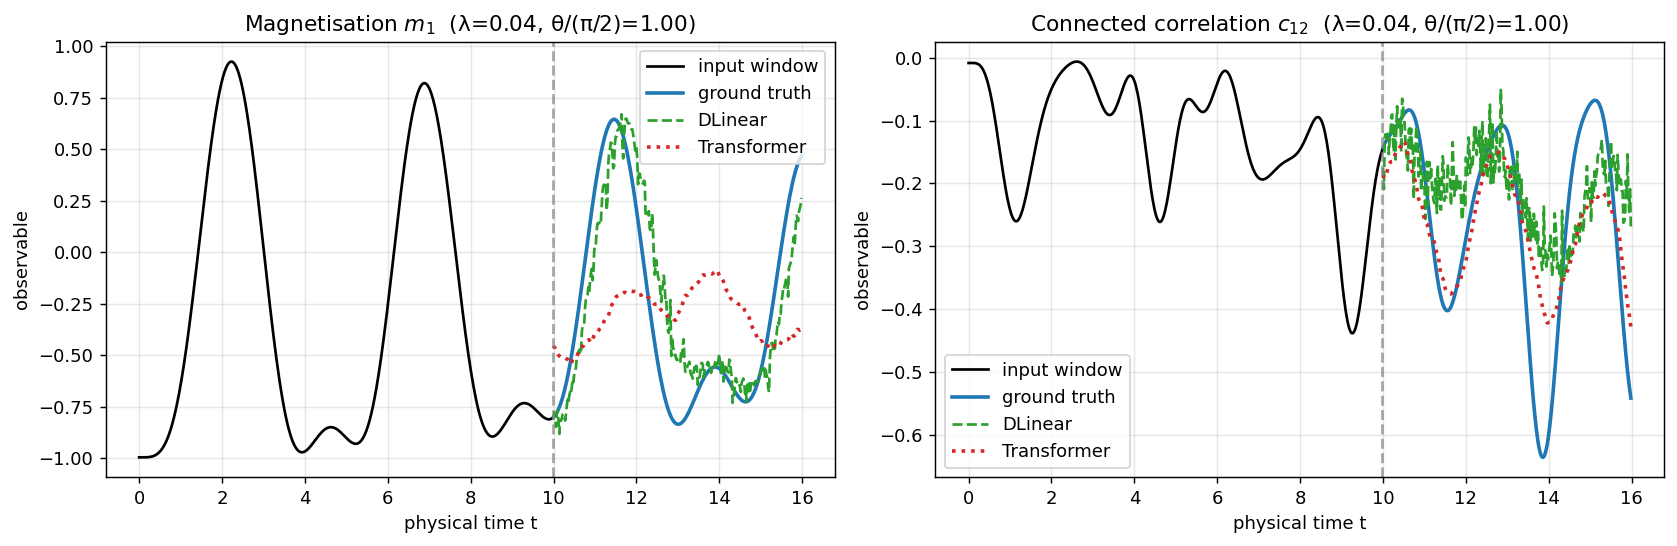

In [11]:
# ---------------- sample forecast: worst Transformer trajectory (m_1 and c_12) ----------------
traj_mae_dl, traj_mae_tf = mae_per_traj(Y_test_phys, pred_dl), mae_per_traj(Y_test_phys, pred_tf)
sid = int(np.argmax(traj_mae_tf))
t_in, t_out = time_grid[:RHO], time_grid[RHO:]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), dpi=130)
for ax, fi, fname in zip(axes, [0, N_MAG], ["Magnetisation $m_1$", "Connected correlation $c_{12}$"]):
    ax.plot(t_in,  X_test_phys[sid, :, fi], color="black", label="input window")
    ax.plot(t_out, Y_test_phys[sid, :, fi], color="tab:blue", lw=2, label="ground truth")
    ax.plot(t_out, pred_dl[sid, :, fi], "--", color="tab:green", lw=1.5, label="DLinear")
    ax.plot(t_out, pred_tf[sid, :, fi], ":", color="tab:red", lw=2, label="Transformer")
    ax.axvline(t_in[-1], color="gray", ls="--", alpha=.7)
    ax.set_title(f"{fname}  ({PARAM_LABELS[0]}={P_test_plot[sid,0]:.2f}, {PARAM_LABELS[1]}={P_test_plot[sid,1]:.2f})")
    ax.set_xlabel("physical time t"); ax.set_ylabel("observable"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/trajectory_forecast_m1_c12.png", dpi=200); plt.show()

# 7 Paper Figs. 4, 3 and 5: error propagation, best/typical/worst heat-maps, site-resolved distributions

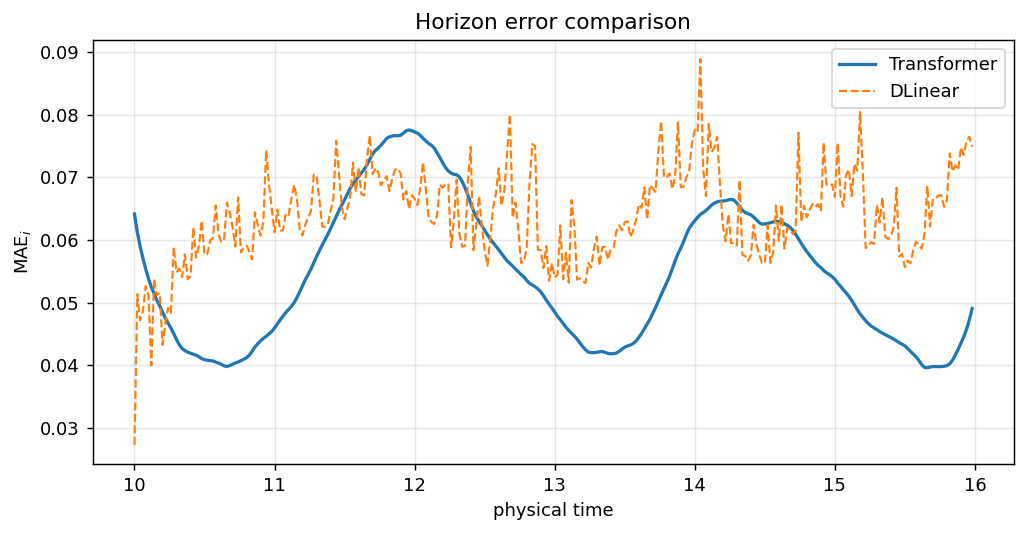

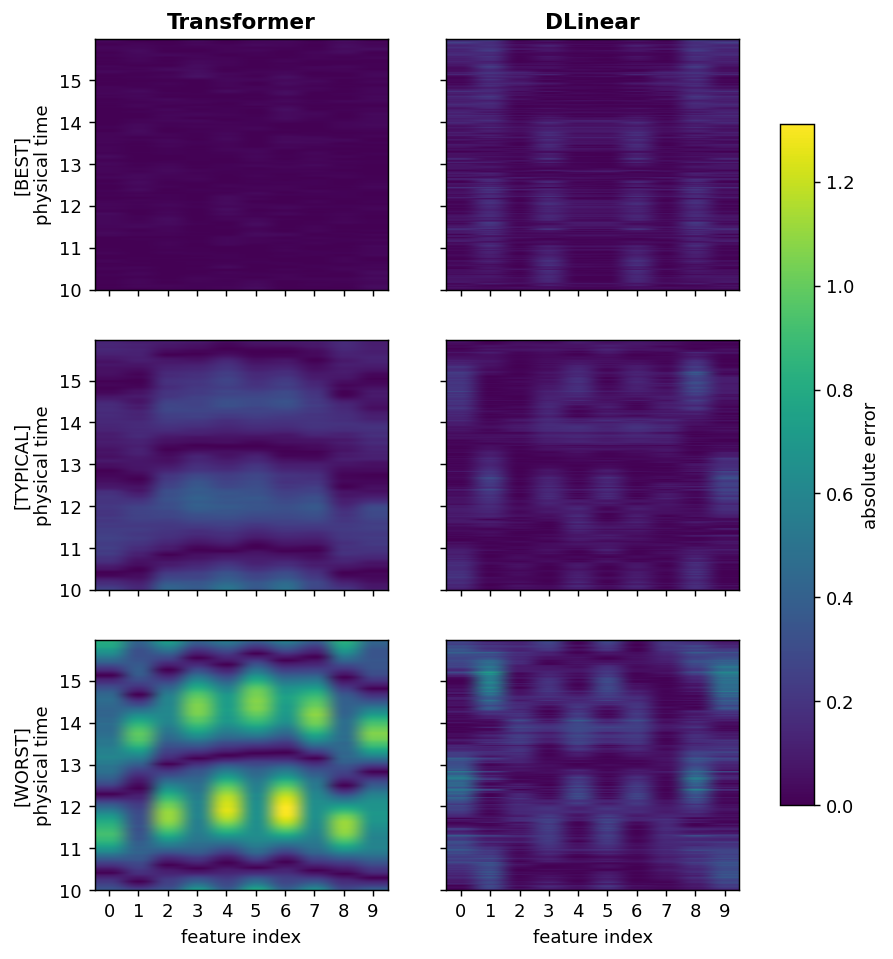

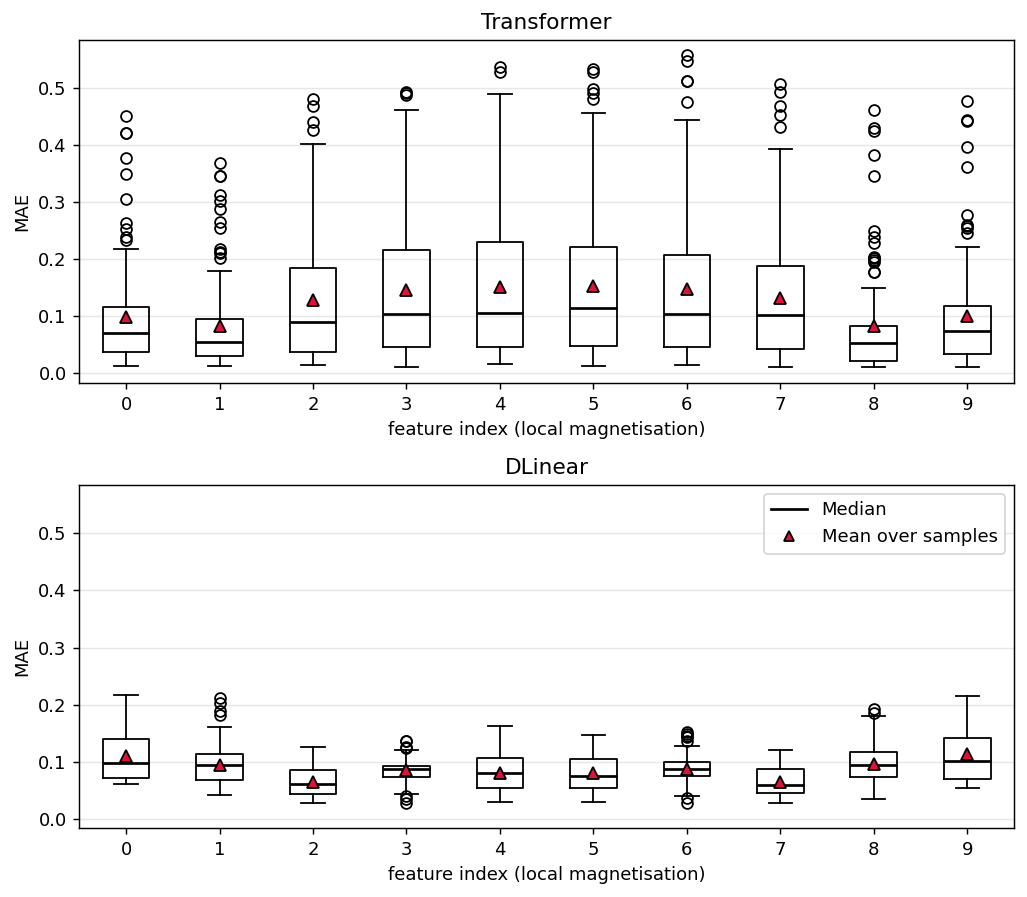

In [12]:
# ---------------- Fig. 4: MAE_i versus physical time (Eq. 23) ----------------
mae_h_dl = np.mean(np.abs(Y_test_phys - pred_dl), axis=(0, 2))
mae_h_tf = np.mean(np.abs(Y_test_phys - pred_tf), axis=(0, 2))
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=130)
ax.plot(t_out, mae_h_tf, "-", color="tab:blue", lw=1.8, label="Transformer")
ax.plot(t_out, mae_h_dl, "--", color="tab:orange", lw=1.2, label="DLinear")
ax.set_xlabel("physical time"); ax.set_ylabel("MAE$_i$"); ax.set_title("Horizon error comparison"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_horizon_error.png", dpi=200); plt.show()

# ---------------- Fig. 3: AE heat-maps for best / typical / worst trajectories (first L features) ----------------
joint = 0.5 * (traj_mae_dl + traj_mae_tf)
best_idx, worst_idx = int(np.argmin(joint)), int(np.argmax(joint))
typical_idx = int(np.argmin(np.abs(joint - joint.mean())))
ae_tf = np.abs(Y_test_phys[:, :, :N_MAG] - pred_tf[:, :, :N_MAG])
ae_dl = np.abs(Y_test_phys[:, :, :N_MAG] - pred_dl[:, :, :N_MAG])
sel = [best_idx, typical_idx, worst_idx]
vmax_ae = max(ae_tf[sel].max(), ae_dl[sel].max())
fig, axes = plt.subplots(3, 2, figsize=(8, 8.5), dpi=130, sharex=True, sharey=True)
for r, (idx, lab) in enumerate(zip(sel, ["BEST", "TYPICAL", "WORST"])):
    for c, (ae, nm) in enumerate([(ae_tf, "Transformer"), (ae_dl, "DLinear")]):
        im = axes[r, c].imshow(ae[idx], aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=vmax_ae,
                               extent=[-0.5, N_MAG - 0.5, t_out[0], t_out[-1]])
        if r == 0: axes[r, c].set_title(nm, fontweight="bold")
        if c == 0: axes[r, c].set_ylabel(f"[{lab}]\nphysical time")
        if r == 2: axes[r, c].set_xlabel("feature index")
        axes[r, c].set_xticks(range(N_MAG))
fig.colorbar(im, ax=axes.ravel().tolist(), label="absolute error", shrink=0.8)
plt.savefig(f"{FIG_DIR}/fig3_ae_heatmaps.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------------- Fig. 5: site-resolved MAE_{k,f} distributions (Eq. 24) ----------------
site_tf = np.mean(np.abs(Y_test_phys[:, :, :N_MAG] - pred_tf[:, :, :N_MAG]), axis=1)     # (N_test, L)
site_dl = np.mean(np.abs(Y_test_phys[:, :, :N_MAG] - pred_dl[:, :, :N_MAG]), axis=1)
fig, axes = plt.subplots(2, 1, figsize=(8, 7), dpi=130, sharey=True)
for ax, data, title in zip(axes, [site_tf, site_dl], ["Transformer", "DLinear"]):
    kw = dict(showmeans=True, medianprops=dict(color="black", lw=1.5),
              meanprops=dict(marker="^", markeredgecolor="black", markerfacecolor="crimson", markersize=7))
    cols = [data[:, j] for j in range(N_MAG)]; labs = [str(j) for j in range(N_MAG)]
    try:    ax.boxplot(cols, tick_labels=labs, **kw)            # Matplotlib >= 3.9
    except TypeError: ax.boxplot(cols, labels=labs, **kw)       # older Matplotlib
    ax.set_title(title); ax.set_xlabel("feature index (local magnetisation)"); ax.set_ylabel("MAE"); ax.grid(axis="y", alpha=.3)
axes[1].plot([], [], color="black", lw=1.5, label="Median"); axes[1].plot([], [], "^", mfc="crimson", mec="black", label="Mean over samples"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_feature_boxplots.png", dpi=200); plt.show()

# 8 Does this run support the paper's qualitative claims?

The paper reports no numeric table, only figures, so the check below turns its statements into explicit tests (PXP data only). The thresholds are rough and meant to be read together with the printed numbers. A claim shown as **no** is not an error in the code; with the reduced presets or few epochs it is expected.

In [13]:
if DATA_SOURCE != "pxp":
    print("Claims check is defined for the PXP dataset only.")
else:
    hi = P_test_plot[:, 1] > 0.5        # theta > pi/4  (Neel / scarred side)
    lo = ~hi
    res = []
    def add(claim, ok, detail): res.append((claim, "yes" if ok else "NO", detail))

    da_raw_dl = maps[("DLinear", None)][1]
    add("DLinear raw DA is close to chance (~50 %), uniform over the plane",
        abs(da_raw_dl.mean() - 50) < 12 and da_raw_dl.std() < 8, f"mean {da_raw_dl.mean():.1f} %, std {da_raw_dl.std():.1f}")

    w_mid = [w for w in SG_WINDOWS if 20 <= w <= 60]
    if w_mid:
        best = max(w_mid, key=lambda w: maps[("DLinear", w)][1].mean()); da_b = maps[("DLinear", best)][1]
        add("Smoothing lifts DLinear DA far above 50 % (>90 % on a large part of the plane) for w in [20,60]",
            (da_b > 90).mean() > 0.4, f"w={best}: mean {da_b.mean():.1f} %, {100*(da_b>90).mean():.0f} % of trajectories >90 %")

    d_tf = maps[("Transformer", None)][1]
    add("Transformer DA depends on theta (higher for theta<pi/4)", d_tf[lo].mean() > d_tf[hi].mean() + 3,
        f"theta<pi/4: {d_tf[lo].mean():.1f} %  vs  theta>pi/4: {d_tf[hi].mean():.1f} %")

    m_tf, m_dl = maps[("Transformer", None)][0], maps[("DLinear", None)][0]
    add("Transformer MAE rises for theta>pi/4", m_tf[hi].mean() > 1.3 * m_tf[lo].mean(), f"{m_tf[lo].mean():.4f} -> {m_tf[hi].mean():.4f}")
    add("DLinear MAE is roughly uniform over theta", m_dl[hi].mean() < 1.3 * m_dl[lo].mean(), f"{m_dl[lo].mean():.4f} vs {m_dl[hi].mean():.4f}")
    add("DLinear has lower global MAE than the Transformer", m_dl.mean() < m_tf.mean(), f"{m_dl.mean():.4f} vs {m_tf.mean():.4f}")
    add("DLinear mean MAE_{k,f} is lower for every local magnetisation", bool(np.all(site_dl.mean(0) < site_tf.mean(0))),
        f"{int((site_dl.mean(0) < site_tf.mean(0)).sum())}/{N_MAG} sites")
    add("Transformer error distribution is right-skewed (mean > median) on most sites", (site_tf.mean(0) > np.median(site_tf, 0)).sum() >= 0.7 * N_MAG,
        f"{int((site_tf.mean(0) > np.median(site_tf, 0)).sum())}/{N_MAG} sites")
    q = len(mae_h_tf) // 4
    add("DLinear horizon error saturates while the Transformer's keeps growing",
        (mae_h_dl[-q:].mean() / mae_h_dl[q:2*q].mean()) < (mae_h_tf[-q:].mean() / mae_h_tf[q:2*q].mean()),
        f"last/second-quarter ratio: DLinear {mae_h_dl[-q:].mean()/mae_h_dl[q:2*q].mean():.2f}, Transformer {mae_h_tf[-q:].mean()/mae_h_tf[q:2*q].mean():.2f}")
    add("Both models beat the persistence baseline in MAE", max(m_dl.mean(), m_tf.mean()) < df_eval.loc["Persistence (last value)", "MAE total"],
        f"DLinear {m_dl.mean():.4f}, Transformer {m_tf.mean():.4f}, persistence {df_eval.loc['Persistence (last value)', 'MAE total']:.4f}")
    display(pd.DataFrame(res, columns=["Paper claim", "Reproduced?", "Evidence"]).style.hide(axis="index"))

Paper claim,Reproduced?,Evidence
"DLinear raw DA is close to chance (~50 %), uniform over the plane",yes,"mean 56.1 %, std 3.7"
"Smoothing lifts DLinear DA far above 50 % (>90 % on a large part of the plane) for w in [20,60]",NO,"w=60: mean 79.0 %, 18 % of trajectories >90 %"
Transformer DA depends on theta (higher for theta<pi/4),NO,thetapi/4: 78.3 %
Transformer MAE rises for theta>pi/4,yes,0.0291 -> 0.0808
DLinear MAE is roughly uniform over theta,yes,0.0627 vs 0.0649
DLinear has lower global MAE than the Transformer,NO,0.0638 vs 0.0544
"DLinear mean MAE_{k,f} is lower for every local magnetisation",NO,6/10 sites
Transformer error distribution is right-skewed (mean > median) on most sites,yes,10/10 sites
DLinear horizon error saturates while the Transformer's keeps growing,NO,"last/second-quarter ratio: DLinear 0.99, Transformer 0.74"
Both models beat the persistence baseline in MAE,yes,"DLinear 0.0638, Transformer 0.0544, persistence 0.1254"


# 9 Extensions beyond the paper (kept from the original notebook, now consistent with the main protocol)

These experiments are **not** in the paper. They use the same informed loss, scaled data, physical-unit evaluation and the autoregressive Transformer. In the `paper` preset the ablations use the lighter Transformer `CFG["abl_tf"]` to keep the runtime manageable. Set `RUN_EXTENSIONS = False` to skip them.

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (32, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Transformer             -> test MAE 0.05444 | DA 79.34 %
Conditioned Transformer -> test MAE 0.04726 | DA 79.40 %


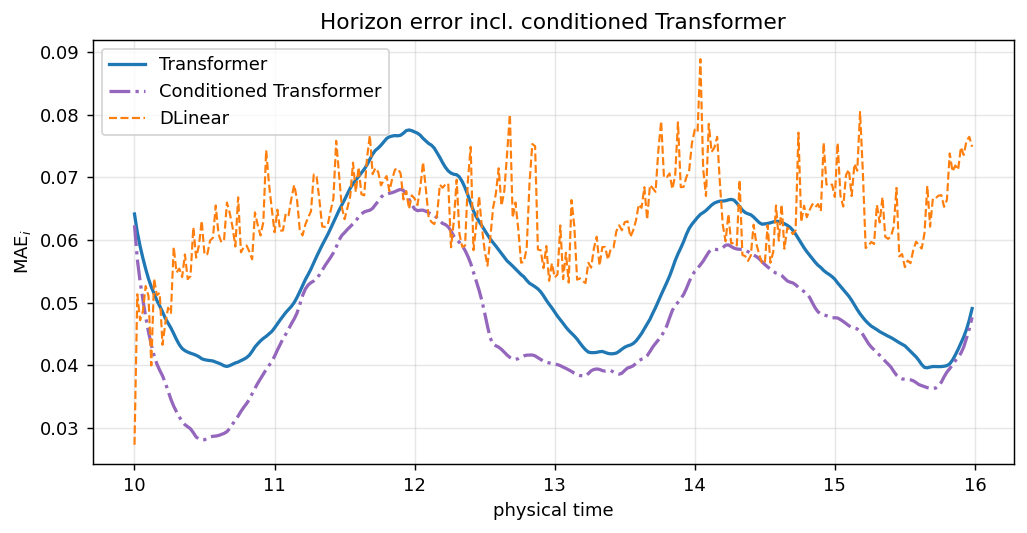

In [14]:
RUN_EXTENSIONS = True
ABL_HP = {"dlinear": {}, "transformer": CFG["abl_tf"]}

def test_mae(fc, P=None):
    return float(np.mean(np.abs(Y_test_phys - to_phys(fc.predict(X_test, P)))))

if RUN_EXTENSIONS:
    # ---- 9a  parameter-conditioned Transformer: lambda/theta (or Omega/Delta) injected into encoder and decoder ----
    fc_cond = Forecaster("transformer", RHO, TAU, F, cond_dim=P_dev_s.shape[1]).fit(X_dev, Y_dev, P=P_dev_s)
    pred_cond = to_phys(fc_cond.predict(X_test, P_test_s))
    print(f"Transformer             -> test MAE {np.mean(np.abs(Y_test_phys - pred_tf)):.5f} | DA {compute_directional_accuracy(Y_test_phys, pred_tf, X_test_phys):.2f} %")
    print(f"Conditioned Transformer -> test MAE {np.mean(np.abs(Y_test_phys - pred_cond)):.5f} | DA {compute_directional_accuracy(Y_test_phys, pred_cond, X_test_phys):.2f} %")

    fig, ax = plt.subplots(figsize=(8, 4.2), dpi=130)
    ax.plot(t_out, mae_h_tf, "-", color="tab:blue", lw=1.8, label="Transformer")
    ax.plot(t_out, np.mean(np.abs(Y_test_phys - pred_cond), axis=(0, 2)), "-.", color="tab:purple", lw=1.8, label="Conditioned Transformer")
    ax.plot(t_out, mae_h_dl, "--", color="tab:orange", lw=1.2, label="DLinear")
    ax.set_xlabel("physical time"); ax.set_ylabel("MAE$_i$"); ax.set_title("Horizon error incl. conditioned Transformer"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ext_horizon_error_conditioned.png", dpi=200); plt.show()

E0000 00:00:1793830903.900507      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793830909.403149      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

N_train =  25 | DLinear 0.13481 | Transformer 0.15390


E0000 00:00:1793830946.384837      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793830951.845628      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

N_train =  50 | DLinear 0.13636 | Transformer 0.12358


E0000 00:00:1793830987.581535      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793830994.612914      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

N_train = 100 | DLinear 0.09856 | Transformer 0.11650


E0000 00:00:1793831034.660824      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831042.321948      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

N_train = 200 | DLinear 0.08843 | Transformer 0.10675


E0000 00:00:1793831093.914564      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831102.955657      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

N_train = 400 | DLinear 0.07768 | Transformer 0.09310


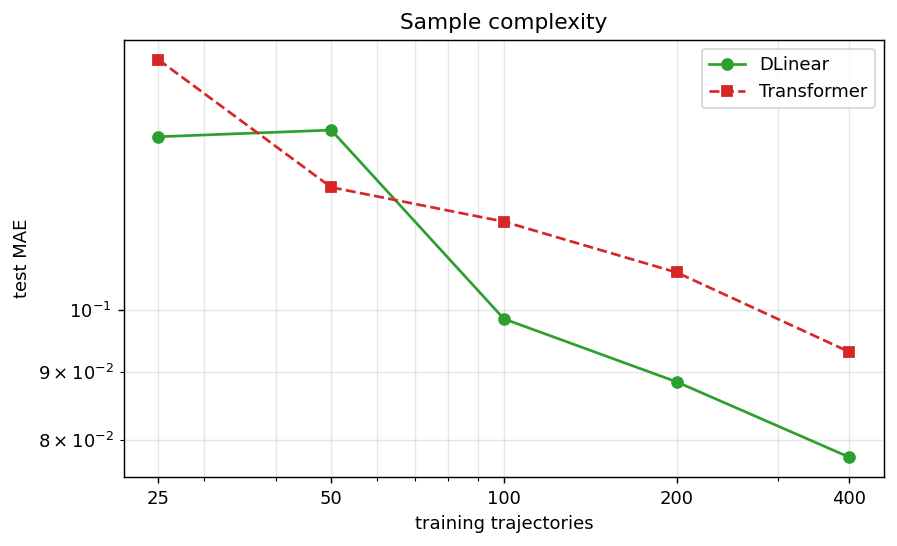

In [15]:
if RUN_EXTENSIONS:
    # ---- 9b  sample complexity: test MAE vs number of training trajectories ----
    sizes = [n for n in CFG["train_sizes"] if n <= len(X_dev)]
    mae_sc = {"dlinear": [], "transformer": []}
    for n_tr in sizes:
        for kind in mae_sc:
            fc = Forecaster(kind, RHO, TAU, F, hp=ABL_HP[kind]).fit(X_dev[:n_tr], Y_dev[:n_tr], epochs=CFG["abl_epochs"])
            mae_sc[kind].append(test_mae(fc))
        print(f"N_train = {n_tr:3d} | DLinear {mae_sc['dlinear'][-1]:.5f} | Transformer {mae_sc['transformer'][-1]:.5f}")
    fig, ax = plt.subplots(figsize=(7, 4.3), dpi=130)
    ax.plot(sizes, mae_sc["dlinear"], "o-", color="tab:green", label="DLinear")
    ax.plot(sizes, mae_sc["transformer"], "s--", color="tab:red", label="Transformer")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(sizes); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_xlabel("training trajectories"); ax.set_ylabel("test MAE"); ax.set_title("Sample complexity"); ax.legend(); ax.grid(which="both", alpha=.3)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ext_sample_complexity.png", dpi=200); plt.show()

E0000 00:00:1793831172.109680      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831179.934671      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

rho=100 | A: DLinear 0.09787, Transf 0.09536 | B: DLinear 0.09477, Transf 0.10605


E0000 00:00:1793831344.855837      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831352.917383      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

rho=200 | A: DLinear 0.08550, Transf 0.09457 | B: DLinear 0.08410, Transf 0.10255


E0000 00:00:1793831506.026420      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831514.281605      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

rho=300 | A: DLinear 0.08290, Transf 0.09420 | B: DLinear 0.08093, Transf 0.09829


E0000 00:00:1793831664.388917      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831672.990305      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

rho=400 | A: DLinear 0.07999, Transf 0.09336 | B: DLinear 0.07955, Transf 0.09661


E0000 00:00:1793831818.291810      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793831827.164998      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

rho=500 | A: DLinear 0.07768, Transf 0.09310 | B: DLinear 0.07768, Transf 0.09310


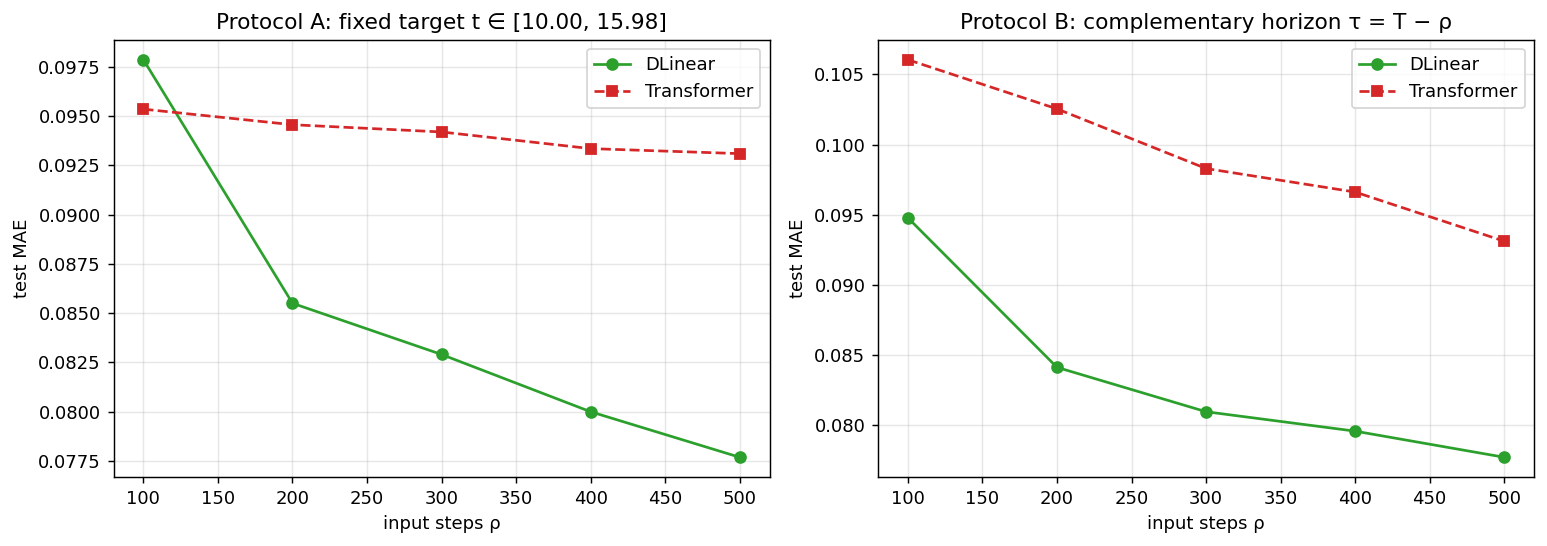

In [16]:
if RUN_EXTENSIONS:
    # ---- 9c  input-horizon ablation ----
    # Protocol A: fixed target window [RHO:T] predicted from the rho steps that precede it.
    # Protocol B: complementary split [0:rho] -> [rho:T] (the horizon grows as the input shrinks).
    rho_list = [r for r in CFG["rho_list"] if r <= RHO]
    res_A = {"dlinear": [], "transformer": []}; res_B = {"dlinear": [], "transformer": []}
    def fit_eval(kind, rho_i, tau_i, start_in, start_out):
        Xtr, Ytr = obs_dev_s[:, start_in:start_in + rho_i], obs_dev_s[:, start_out:start_out + tau_i]
        Xte, Yte = obs_test_s[:, start_in:start_in + rho_i], obs_test_raw[:, start_out:start_out + tau_i]
        fc = Forecaster(kind, rho_i, tau_i, F, hp=ABL_HP[kind]).fit(Xtr, Ytr, epochs=CFG["abl_epochs"])
        return float(np.mean(np.abs(Yte - to_phys(fc.predict(Xte)))))
    for rho_i in rho_list:
        for kind in res_A:
            res_A[kind].append(fit_eval(kind, rho_i, T - RHO, RHO - rho_i, RHO))        # A
            res_B[kind].append(fit_eval(kind, rho_i, T - rho_i, 0, rho_i))               # B
        print(f"rho={rho_i:3d} | A: DLinear {res_A['dlinear'][-1]:.5f}, Transf {res_A['transformer'][-1]:.5f} | B: DLinear {res_B['dlinear'][-1]:.5f}, Transf {res_B['transformer'][-1]:.5f}")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), dpi=130)
    for ax, res, ttl in zip(axes, [res_A, res_B], [f"Protocol A: fixed target t ∈ [{time_grid[RHO]:.2f}, {time_grid[-1]:.2f}]", "Protocol B: complementary horizon τ = T − ρ"]):
        ax.plot(rho_list, res["dlinear"], "o-", color="tab:green", label="DLinear")
        ax.plot(rho_list, res["transformer"], "s--", color="tab:red", label="Transformer")
        ax.set_title(ttl); ax.set_xlabel("input steps ρ"); ax.set_ylabel("test MAE"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ext_input_horizon.png", dpi=200); plt.show()

# 10 Caveats worth keeping in mind when reading the results

* **DA after smoothing is not a like-for-like comparison.** The raw DLinear DA sits near chance; the >90 % figures come from smoothing the *prediction* (not the ground truth) with a Savitzky–Golay filter. This shows that the residual error is high-frequency, but the raw directional accuracy is still ≈ 50 %. Read DA together with MAE and the baselines in Section 6.
* **The DA result depends on initialisation (measured in this environment, one seed).** With the default Glorot initialisation DLinear gives test MAE ≈ 0.064, raw DA ≈ 56 % (chance level, uniform over the plane) and DA ≈ 78 % after Savitzky–Golay smoothing, qualitatively the paper's picture. With the reference-DLinear constant $1/\rho$ initialisation the same model gives MAE ≈ 0.060 and raw DA ≈ 80 %, unchanged by smoothing. So the "high-frequency oscillations" are at least partly a leftover of random initial weights that the data and the weak L2 term do not remove, and they are not a property of the quantum signal. Test it with `Forecaster("dlinear", ..., hp=dict(init="inv_rho"))`.
* **Baselines.** MAE values are only meaningful relative to a reference; persistence and window-mean are included for that purpose. A linear map can in principle represent any (quasi-)periodic signal exactly, which is a plausible reason for DLinear's good performance in the scarred regime; the notebook does not test this.
* **Scope.** Single system size ($L=10$), one split and one seed. The paper itself states these limits; for stronger conclusions repeat Section 6 over several seeds (`SEED`) and report the spread.
* **Transformer training description** differs between Secs. 3.2.2 and 3.3.1 of the paper (see the header of this notebook); this notebook follows Sec. 3.3.1.

## if i have a question

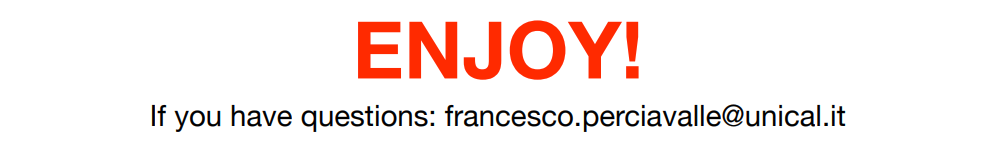